In [ ]:
  %pip install -q ultralytics

import torch

print("GPU 사용 가능:", torch.cuda.is_available())

GPU 사용 가능: True


In [ ]:
from google.colab import files

uploaded = files.upload()
print("업로드한 파일:", list(uploaded.keys()))

Saving recycling_yolo_starter (1).zip to recycling_yolo_starter (1).zip
업로드한 파일: ['recycling_yolo_starter (1).zip']


In [ ]:
from pathlib import Path
import zipfile
import yaml

# 방금 업로드한 ZIP 파일 선택
zip_files = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
assert len(zip_files) == 1, "starter ZIP 파일 하나만 업로드해 주세요."

# 원래 계획한 데이터인지 압축 내부부터 확인
with zipfile.ZipFile(zip_files[0]) as z:
    expected = "recycling_yolo_starter/data.yaml"

    assert expected in z.namelist(), (
        "선택한 파일이 starter 데이터가 아닙니다. "
        "recycling_yolo_starter.zip을 업로드해 주세요."
    )

    z.extractall("/content/starter_data")

root = Path("/content/starter_data/recycling_yolo_starter")
yaml_path = root / "data.yaml"

with open(yaml_path, encoding="utf-8") as f:
    config = yaml.safe_load(f)

config["path"] = str(root)

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, allow_unicode=True)

print("분류 종류:", config["names"])

for split in ["train", "val", "test"]:
    count = sum(
        p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        for p in (root / "images" / split).iterdir()
    )
    print(split, count, "장")

분류 종류: {0: 'plastic', 1: 'paper', 2: 'metal'}
train 720 장
val 90 장
test 90 장


In [ ]:
from pathlib import Path
from ultralytics import YOLO

assert torch.cuda.is_available(), (
    "GPU를 사용할 수 없습니다. 코랩에서 GPU 런타임을 설정해 주세요."
)

# 사전 학습된 모델 불러오기
model = YOLO("yolo11n.pt")

# 우리 데이터로 추가 학습하기
model.train(
    data=str(yaml_path),
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    project="/content/recycling_runs",
    name="baseline",
    seed=42
)

# 이번 학습에서 실제로 사용한 저장 경로
run_dir = Path(model.trainer.save_dir)
best_path = run_dir / "weights" / "best.pt"

print("학습 결과 폴더:", run_dir)
print("학습된 모델:", best_path)

Ultralytics 8.4.164 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/starter_data/recycling_yolo_starter/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline-2, nbs=64, nms=None, opset

KeyboardInterrupt: 

In [ ]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "/content/recycling_first_run",
    "zip",
    root_dir=str(run_dir)
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving ChatGPT 이미지 2026년 9월 29일 오전 02_21_20.jpg to ChatGPT 이미지 2026년 9월 29일 오전 02_21_20.jpg

0: 640x480 1 plastic, 7.7ms
Speed: 3.2ms preprocess, 7.7ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 480)
사진: ChatGPT 이미지 2026년 9월 29일 오전 02_21_20.jpg
찾은 물체 수: 1


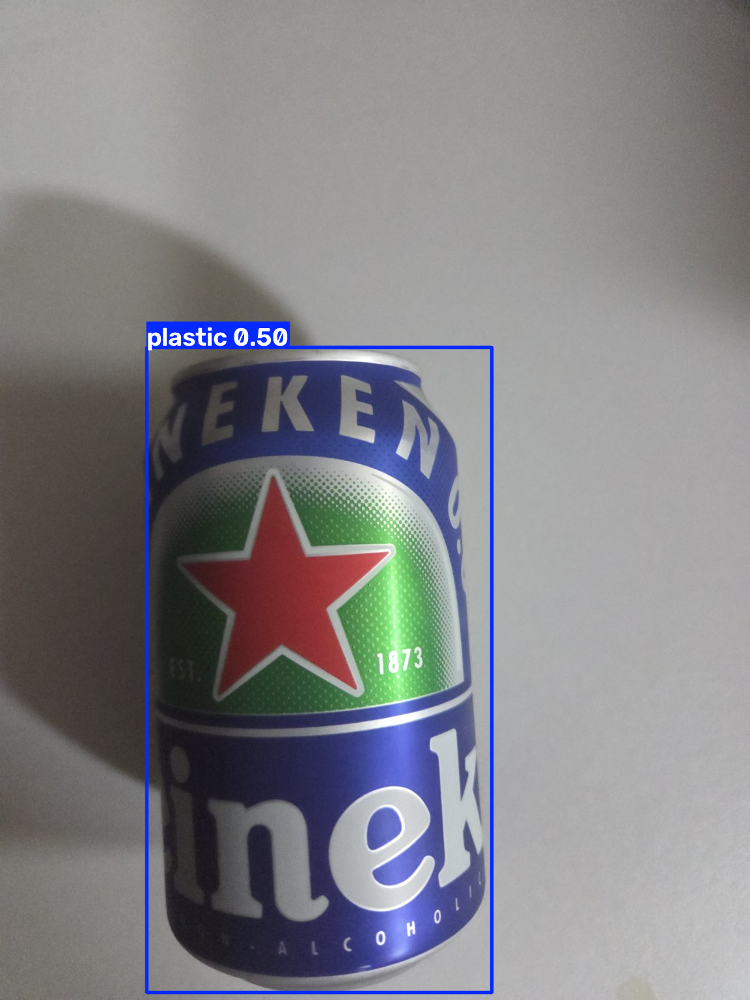

In [ ]:
from ultralytics import YOLO
from google.colab import files
from PIL import Image
from IPython.display import display
import io

# 이번에 학습한 모델 불러오기
trained_model = YOLO(str(best_path))

# 테스트할 사진 업로드
photos = files.upload()

for filename, data in photos.items():
    photo = Image.open(io.BytesIO(data)).convert("RGB")

    result = trained_model.predict(
        photo,
        conf=0.25
    )[0]

    print("사진:", filename)
    print("찾은 물체 수:", len(result.boxes))

    annotated = result.plot()
    display(Image.fromarray(annotated[:, :, ::-1]))

In [ ]:
from pathlib import Path
import torch

root = Path("/content/starter_data/recycling_yolo_starter")

print("GPU 사용 가능:", torch.cuda.is_available())
print("기존 데이터 설정 있음:", (root / "data.yaml").exists())

for split in ["train", "val", "test"]:
    folder = root / "images" / split
    count = sum(
        p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        for p in folder.glob("*")
        if p.is_file()
    )
    print(f"{split}: {count}장")

GPU 사용 가능: True
기존 데이터 설정 있음: False
train: 0장
val: 0장
test: 0장


In [ ]:
from google.colab import files

uploaded = files.upload()
print("업로드 완료:", list(uploaded.keys()))

Saving recycling_yolo_starter (1).zip to recycling_yolo_starter (1).zip
업로드 완료: ['recycling_yolo_starter (1).zip']


In [ ]:
from google.colab import files

extra_uploaded = files.upload()

Saving recycling_supplement_v1.zip to recycling_supplement_v1.zip


In [ ]:
from pathlib import Path
import zipfile
import shutil
import yaml

content = Path("/content")

# ZIP 내부의 폴더 구조로 파일 찾기
def find_zip(required_file):
    candidates = []
    for path in content.glob("*.zip"):
        if zipfile.is_zipfile(path):
            with zipfile.ZipFile(path) as z:
                if required_file in z.namelist():
                    candidates.append(path)

    if not candidates:
        raise FileNotFoundError(
            f"필요한 ZIP을 찾지 못했습니다: {required_file}"
        )

    return max(candidates, key=lambda p: p.stat().st_mtime)

starter_zip = find_zip("recycling_yolo_starter/data.yaml")
extra_zip = find_zip("recycling_supplement_v1/README.txt")

print("기존 데이터:", starter_zip.name)
print("추가 데이터:", extra_zip.name)

# 기존 학습과 구분되는 폴더에 압축 풀기
work = content / "recycling_data_v2"
work.mkdir(exist_ok=True)

for zip_path in [starter_zip, extra_zip]:
    with zipfile.ZipFile(zip_path) as z:
        # 압축 파일이 지정 폴더 밖에 파일을 쓰지 않도록 확인
        for name in z.namelist():
            target = (work / name).resolve()
            if not target.is_relative_to(work.resolve()):
                raise ValueError("압축 내부 경로를 확인해 주세요.")
        z.extractall(work)

root = work / "recycling_yolo_starter"
extra = work / "recycling_supplement_v1"

# 추가 자료는 train에만 복사
# 같은 셀을 다시 실행해도 동일 파일을 덮어써 중복되지 않음
for kind, suffix in [("images", ".jpg"), ("labels", ".txt")]:
    destination = root / kind / "train"
    destination.mkdir(parents=True, exist_ok=True)

    for source in (extra / kind / "train").glob(f"*{suffix}"):
        shutil.copy2(source, destination / source.name)

# 학습 설정 경로 수정
yaml_path = root / "data.yaml"

with yaml_path.open(encoding="utf-8") as f:
    config = yaml.safe_load(f)

config["path"] = str(root)
config["train"] = "images/train"
config["val"] = "images/val"
config["test"] = "images/test"

with yaml_path.open("w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, allow_unicode=True)

print("\n분류 종류:", config["names"])

expected = {"train": 731, "val": 90, "test": 90}

for split, expected_count in expected.items():
    images = [
        p for p in (root / "images" / split).iterdir()
        if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
    ]
    print(f"{split}: {len(images)}장")

    assert len(images) == expected_count, (
        f"{split} 사진 수가 예상과 다릅니다. 출력 내용을 보내주세요."
    )

    for photo in images:
        label = root / "labels" / split / f"{photo.stem}.txt"
        assert label.exists(), f"정답 파일 없음: {label.name}"

print("\n데이터 합치기 완료! 아직 학습은 시작하지 않았습니다.")

기존 데이터: recycling_yolo_starter (1).zip
추가 데이터: recycling_supplement_v1.zip

분류 종류: {0: 'plastic', 1: 'paper', 2: 'metal'}
train: 731장
val: 90장
test: 90장

데이터 합치기 완료! 아직 학습은 시작하지 않았습니다.


In [ ]:
%pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.1 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
from ultralytics import YOLO
import ultralytics
import torch

assert torch.cuda.is_available(), "GPU 연결을 확인해 주세요."

yaml_path = Path(
    "/content/recycling_data_v2/recycling_yolo_starter/data.yaml"
)
assert yaml_path.exists(), "데이터 합치기 셀을 먼저 실행해 주세요."

print("Ultralytics 버전:", ultralytics.__version__)

# 초기 학습과 같은 사전 학습 모델에서 시작
model_v2 = YOLO("yolo11n.pt")

model_v2.train(
    data=str(yaml_path),
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    project="/content/recycling_runs",
    name="supplement_v1",
    seed=42,
    exist_ok=False
)

# 실제 저장 경로 기억하기
run_dir = Path(model_v2.trainer.save_dir)

print("\n학습 완료!")
print("결과 폴더:", run_dir)
print("새 모델:", run_dir / "weights" / "best.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 버전: 8.4.182
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/recycling_data_v2/recycling_yolo_starter/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, flip

In [ ]:
from pathlib import Path
import shutil
from google.colab import files

run_dir = Path("/content/recycling_runs/supplement_v1")
assert (run_dir / "weights" / "best.pt").exists()

archive = shutil.make_archive(
    "/content/recycling_supplement_run_v1",
    "zip",
    root_dir=run_dir
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving KakaoTalk_20261020_014813575.jpg to KakaoTalk_20261020_014813575.jpg

사진: KakaoTalk_20261020_014813575.jpg
탐지 수: 2
  plastic: 77.1%
  plastic: 25.0%


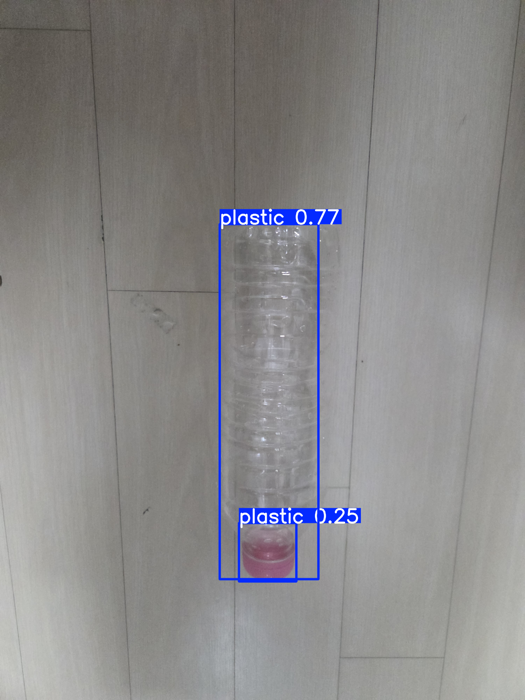

In [ ]:
from ultralytics import YOLO
from google.colab import files
from PIL import Image, ImageOps
from IPython.display import display
import io

new_model = YOLO(
    "/content/recycling_runs/supplement_v1/weights/best.pt"
)

photos = files.upload()

for filename, data in photos.items():
    photo = ImageOps.exif_transpose(
        Image.open(io.BytesIO(data))
    ).convert("RGB")

    result = new_model.predict(
        photo,
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    print("\n사진:", filename)
    print("탐지 수:", len(result.boxes))

    for box in result.boxes:
        label = result.names[int(box.cls.item())]
        confidence = box.conf.item()
        print(f"  {label}: {confidence:.1%}")

    annotated = Image.fromarray(result.plot()[:, :, ::-1])
    annotated.thumbnail((700, 700))
    display(annotated)

In [1]:
from pathlib import Path
from google.colab import files
import json
import shutil

root = Path("/content/recycling_data_v2/recycling_yolo_starter")

if not (root / "labels/train").exists():
    print("기존 데이터가 없습니다. 여기서 멈추고 이 문구를 알려주세요.")
else:
    uploaded = files.upload()
    filename = next(
        name for name in uploaded
        if name.endswith(".json")
    )
    patch = json.loads(uploaded[filename])
    changes = patch["changes"]

    # 수정 전에 모든 파일이 예상한 원본인지 확인
    for item in changes:
        path = root / item["path"]
        current = path.read_text().strip()
        assert current in (
            item["before"].strip(),
            item["after"].strip()
        ), f"원본과 다른 파일입니다: {path.name}"

    # 원본을 백업하고 수정
    backup = root / "label_backup_v1"

    for item in changes:
        path = root / item["path"]
        saved = backup / item["path"]
        saved.parent.mkdir(parents=True, exist_ok=True)

        if not saved.exists():
            shutil.copy2(path, saved)

        path.write_text(item["after"], encoding="utf-8")

    print(f"완료: 학습 사진 {len(changes)}장 라벨 수정")
    print("검증·테스트 데이터는 변경하지 않았습니다.")

기존 데이터가 없습니다. 여기서 멈추고 이 문구를 알려주세요.


In [2]:
from pathlib import Path

configs = list(Path("/content").rglob("data.yaml"))
zips = list(Path("/content").glob("*.zip"))

print("데이터 설정 파일:")
for p in configs:
    print(p)

print("\n압축 파일:")
for p in zips:
    print(p)

if not configs and not zips:
    print("\n데이터를 다시 업로드해야 합니다.")

데이터 설정 파일:

압축 파일:

데이터를 다시 업로드해야 합니다.


In [3]:
from google.colab import files

uploaded = files.upload()

Saving recycling_yolo_starter (1).zip to recycling_yolo_starter (1).zip


In [4]:
from pathlib import Path
import zipfile
import yaml

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]
assert len(zip_names) == 1, "starter ZIP 하나만 업로드해 주세요."

destination = Path("/content/recycling_data_v2")

with zipfile.ZipFile(zip_names[0]) as z:
    z.extractall(destination)

configs = list(destination.rglob("data.yaml"))
assert len(configs) == 1, "설정 파일 개수가 예상과 다릅니다."

yaml_path = configs[0]
root = yaml_path.parent

with open(yaml_path, encoding="utf-8") as f:
    config = yaml.safe_load(f)

config["path"] = str(root)
config["train"] = "images/train"
config["val"] = "images/val"
config["test"] = "images/test"

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, allow_unicode=True)

print("데이터 위치:", root)
print("분류 종류:", config["names"])

for split in ["train", "val", "test"]:
    folder = root / "images" / split
    assert folder.exists(), f"폴더가 없습니다: {folder}"

    count = sum(
        p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        for p in folder.iterdir()
    )
    print(f"{split}: {count}장")

데이터 위치: /content/recycling_data_v2/recycling_yolo_starter
분류 종류: {0: 'plastic', 1: 'paper', 2: 'metal'}
train: 720장
val: 90장
test: 90장


In [5]:
from google.colab import files

supplement_uploaded = files.upload()

Saving recycling_supplement_v1.zip to recycling_supplement_v1.zip


In [6]:
from pathlib import Path
import zipfile

root = Path("/content/recycling_data_v2/recycling_yolo_starter")

zip_names = [
    name for name in supplement_uploaded
    if name.lower().endswith(".zip")
]
assert len(zip_names) == 1, "추가 데이터 ZIP 하나를 선택해 주세요."

with zipfile.ZipFile(zip_names[0]) as z:
    additions = []

    for name in z.namelist():
        if name.endswith("/"):
            continue

        parts = Path(name).parts

        for category in ["images", "labels"]:
            for i in range(len(parts) - 2):
                if parts[i:i + 2] == (category, "train"):
                    target = root / category / "train" / parts[-1]
                    additions.append((name, target))
                    break

    image_count = sum(
        target.parent.parent.name == "images"
        for _, target in additions
    )
    assert image_count == 11, (
        f"추가 사진이 {image_count}장입니다. ZIP 파일을 확인해 주세요."
    )

    for name, target in additions:
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(z.read(name))

for split in ["train", "val", "test"]:
    count = sum(
        p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        for p in (root / "images" / split).iterdir()
    )
    print(f"{split}: {count}장")

train: 731장
val: 90장
test: 90장


In [7]:
from pathlib import Path
from google.colab import files
import json
import shutil

root = Path("/content/recycling_data_v2/recycling_yolo_starter")
assert (root / "labels/train").exists(), "데이터 폴더가 없습니다."

uploaded_patch = files.upload()
names = [name for name in uploaded_patch if name.endswith(".json")]
assert len(names) == 1, "라벨 수정 JSON 파일 하나만 선택해 주세요."

patch = json.loads(uploaded_patch[names[0]])
changes = patch["changes"]

# 모든 파일을 먼저 확인
for item in changes:
    path = root / item["path"]
    current = path.read_text().strip()

    assert current in (
        item["before"].strip(),
        item["after"].strip()
    ), f"예상과 다른 파일입니다: {path.name}"

# 원본 백업 후 수정
for item in changes:
    path = root / item["path"]
    backup = root / "label_backup_v1" / item["path"]
    backup.parent.mkdir(parents=True, exist_ok=True)

    if not backup.exists():
        shutil.copy2(path, backup)

    path.write_text(item["after"], encoding="utf-8")

# 기존 라벨 캐시 제거
for cache in (root / "labels").rglob("*.cache"):
    cache.unlink()

print(f"완료: 학습 사진 {len(changes)}장 라벨 수정")
print("검증·테스트 데이터는 변경하지 않았습니다.")

Saving recycling_label_patch_v1.json to recycling_label_patch_v1.json
완료: 학습 사진 27장 라벨 수정
검증·테스트 데이터는 변경하지 않았습니다.


In [8]:
%pip install -q ultralytics==8.4.182

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 10.7 MB/s eta 0:00:00


In [9]:
from pathlib import Path
import torch
import ultralytics
from ultralytics import YOLO

yaml_path = Path(
    "/content/recycling_data_v2/recycling_yolo_starter/data.yaml"
)

print("Ultralytics 버전:", ultralytics.__version__)
print("GPU 사용 가능:", torch.cuda.is_available())

assert torch.cuda.is_available(), "GPU를 먼저 켜 주세요."
assert yaml_path.exists(), "데이터 설정 파일이 없습니다."

# 이전 실험과 같은 사전 학습 모델에서 시작
model = YOLO("yolo11n.pt")

model.train(
    data=str(yaml_path),
    epochs=20,
    imgsz=640,
    batch=8,
    device=0,
    project="/content/recycling_runs",
    name="label_fix_v1",
    seed=42
)

run_dir = Path(model.trainer.save_dir)
print("학습 완료!")
print("결과 저장 위치:", run_dir)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 버전: 8.4.182
GPU 사용 가능: True
New https://pypi.org/project/ultralytics/8.4.183 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.182 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/recycling_data_v2/recycling_yolo_starter/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=Non

In [10]:
import shutil
from google.colab import files

archive = shutil.make_archive(
    "/content/recycling_label_fix_run_v1",
    "zip",
    root_dir=str(run_dir)
)

files.download(archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saving KakaoTalk_20261020_011740717_11.jpg to KakaoTalk_20261020_011740717_11.jpg

사진: KakaoTalk_20261020_011740717_11.jpg
탐지 수: 1
paper: 43.8%


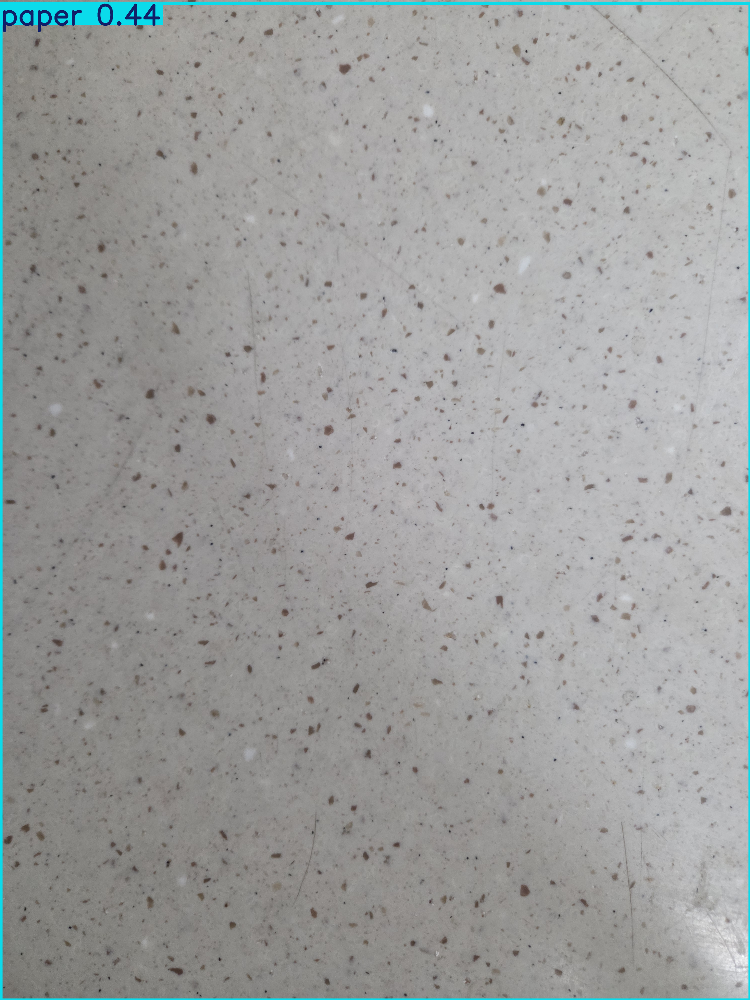

In [14]:
from ultralytics import YOLO
from google.colab import files
from PIL import Image, ImageOps
from IPython.display import display
import io

check_model = YOLO(
    "/content/recycling_runs/label_fix_v1/weights/best.pt"
)

photos = files.upload()

for filename, data in photos.items():
    photo = ImageOps.exif_transpose(
        Image.open(io.BytesIO(data))
    ).convert("RGB")

    result = check_model.predict(
        photo,
        conf=0.25,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    print("\n사진:", filename)
    print("탐지 수:", len(result.boxes))

    for box in result.boxes:
        label = check_model.names[int(box.cls.item())]
        confidence = box.conf.item()
        print(f"{label}: {confidence:.1%}")

    display(Image.fromarray(result.plot()[:, :, ::-1]))